# ANN for the SABR approximation and the SABR integration scheme: McGhee (2018) §5

Train the 14 → N (softplus) → 10 network on the Hagan β=1 dataset (T ∈ [1D, 1Y]) for N ∈ {250, 500, 750, 1000}, then check it against the error ranges the paper reports for Figures 2–6.

Training recipe (the paper's network, loss and optimizer; where the paper is silent we chose):
- one softplus hidden layer, softplus output, MSE on implied vol, Adam, batch 32 (Keras default)
- inputs min-max scaled to [0, 1] on the training set (stored in the model)
- learning rate 1e-3, halved after 100 epochs without a new best loss; stop after 500 epochs without one (≈ 11–15k epochs)

**Log inputs** (`LOG_INPUTS = True`, models `ann_log_{N}`): the network sees (√T, α, ν₁ₘ, ρ, ln K₁..K₁₀) instead of the raw inputs, min-max scaled the same way (`log_features` in `src/model.py`). Sections 3–5 compare them with the raw-input models `ann_{N}` (dashed).

**Section 6** measures ANN accuracy against integration and shows how errors vary across parameters. **Section 7** fits simulated market quotes and compares calibration accuracy and runtime.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy.stats import norm

from src.config import MODEL_DIR, LOG_DIR, DATA_DIR
from src.hagan import COLUMNS_X, COLUMNS_Y, hagan_iv, make_strikes, check_against_paper
from src.model import SABRNet, train

plt.rcParams["figure.dpi"] = 110
torch.manual_seed(0)

## 0. What the SABR parameters do

$$dF = \sigma F^{\beta} dW, \qquad d\sigma = \nu\, \sigma\, dZ, \qquad dW\,dZ = \rho\, dt, \qquad \beta = 1,\ F_0 = 1$$

| Parameter | Paper | Meaning | Effect on the smile | Network domain |
|---|---|---|---|---|
| α | σ(0) | initial volatility | level (≈ ATM vol) | 5–50% |
| ν | ξ | vol of vol | curvature / wing height | ν₁ₘ 5–400%, ν = ν₁ₘ·√(1M/T) (eq. 43) |
| ρ | ρ | correlation of forward and vol shocks | skew: tilt left (ρ < 0) or right (ρ > 0) | −0.9 to +0.9 |
| β | β | backbone exponent | fixed at 1 | – |
| T, K | | maturity, strikes | contract inputs; the ten strikes span ±3.5 sd | 1D–1Y (and 1Y–2Y) |

Each panel varies one parameter around a base case. Solid lines are the integration scheme (the ANN's target), dashed lines the Hagan formula. Each curve spans the network's ±3.5 sd strike range, so wider distributions give wider curves.

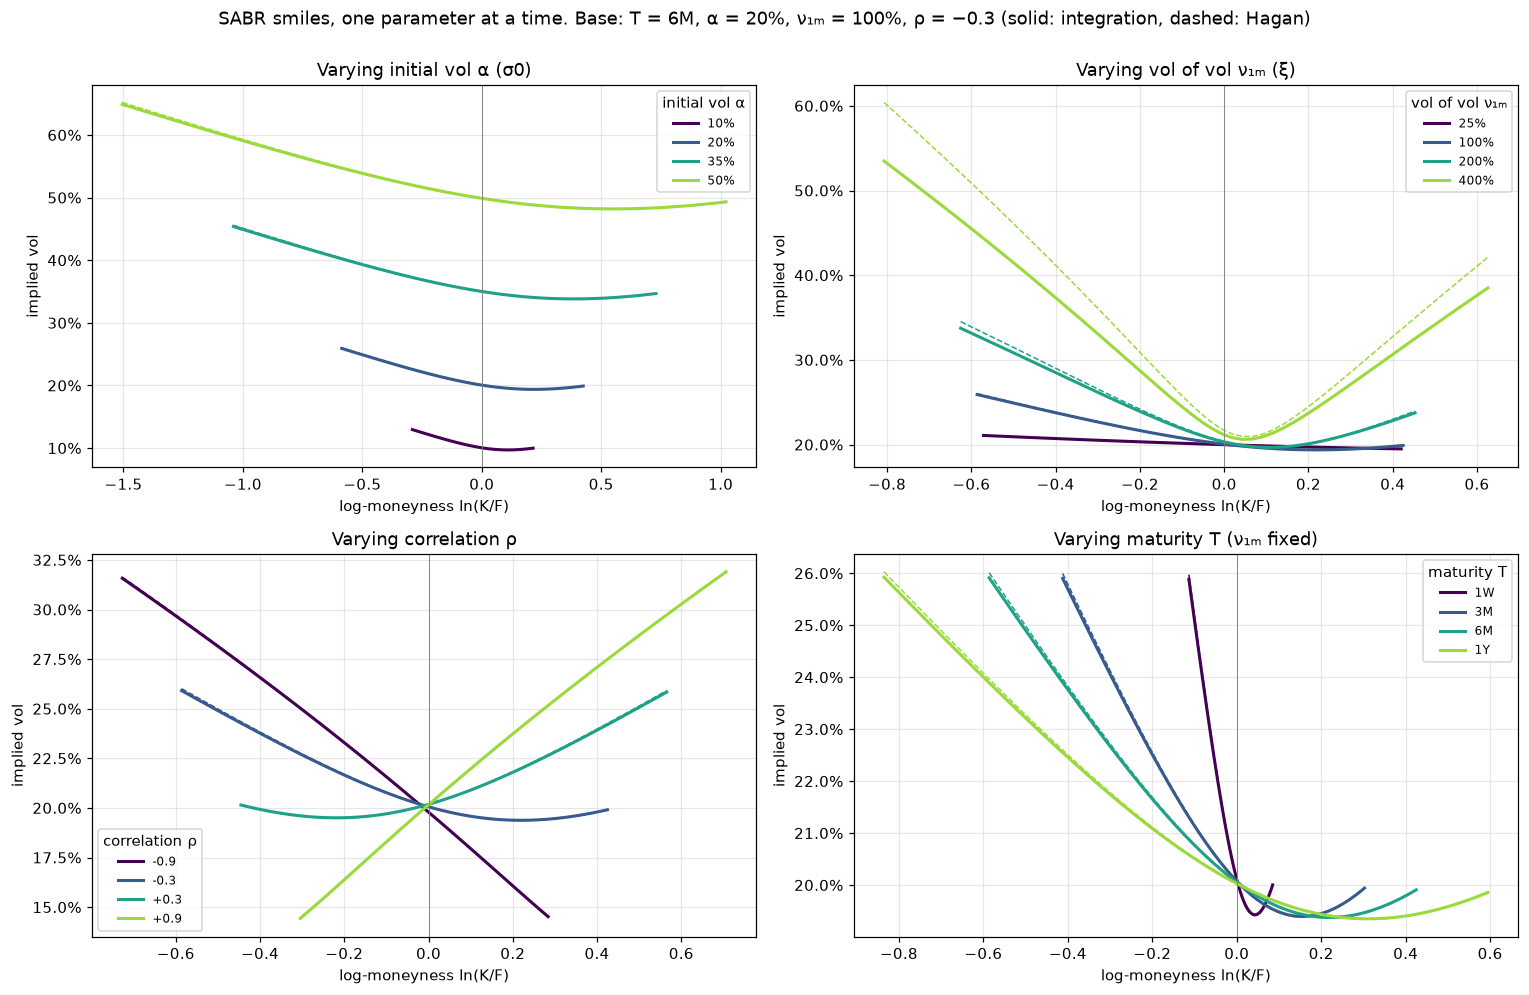

In [2]:
from src import integration as I
from matplotlib.ticker import PercentFormatter

BASE = {"T": 0.5, "alpha": 0.20, "nu1m": 1.0, "rho": -0.3}   # ν₁ₘ = 100%; ν = ν₁ₘ·√(1M/T) (paper eq. 43)
VARY = {
    "alpha": ("initial vol α (σ0)",       [0.10, 0.20, 0.35, 0.50], lambda v: f"{v:.0%}"),
    "nu1m":  ("vol of vol ν₁ₘ (ξ)",       [0.25, 1.0, 2.0, 4.0],    lambda v: f"{v:.0%}"),
    "rho":   ("correlation ρ",            [-0.9, -0.3, 0.3, 0.9],   lambda v: f"{v:+.1f}"),
    "T":     ("maturity T (ν₁ₘ fixed)",   [1/52, 0.25, 0.5, 1.0],   lambda v: {1/52: "1W", 0.25: "3M", 0.5: "6M", 1.0: "1Y"}[v]),
}

def showcase_smile(T, alpha, nu1m, rho, n=60):
    nu = nu1m * np.sqrt(1 / (12 * T))
    K = make_strikes(1.0, T, alpha, rho, nu)              # the network's ±3.5 sd strike range
    Kf = np.geomspace(K[0], K[-1], n)
    integ = I.invert_otm(I.quadrature_price(1.0, Kf, T, alpha, rho, nu), Kf, T)
    return np.log(Kf), integ, hagan_iv(1.0, Kf, T, alpha, 1.0, rho, nu)

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (key, (title, values, fmt)) in zip(axes.ravel(), VARY.items()):
    colors = plt.cm.viridis(np.linspace(0, 0.85, len(values)))
    for v, c in zip(values, colors):
        x, integ, hagan = showcase_smile(**{**BASE, key: v})
        ax.plot(x, integ, color=c, lw=2, label=f"{fmt(v)}")
        ax.plot(x, hagan, color=c, lw=1, ls="--")
    ax.axvline(0, color="grey", lw=0.6)
    ax.set(title=f"Varying {title}", xlabel="log-moneyness ln(K/F)", ylabel="implied vol")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(alpha=0.3); ax.legend(title=title.split(" (")[0], fontsize=8)
fig.suptitle("SABR smiles, one parameter at a time. Base: T = 6M, α = 20%, ν₁ₘ = 100%, ρ = −0.3 "
             "(solid: integration, dashed: Hagan)", y=1.0)
plt.tight_layout(); plt.show()


- **α** mostly shifts the whole smile up; the strike range widens with it because the distribution gets wider.
- **ν** bends the smile into a U. At high ν the Hagan formula (dashed) overshoots the wings: this is exactly where it fails and the integration-trained ANN is needed.
- **ρ** tilts the smile: ρ < 0 gives the equity-style skew (expensive low strikes), ρ > 0 the reverse, ρ ≈ 0 a symmetric smile.
- **T**, with ν₁ₘ held fixed as in the paper's sampling: the strike range grows with √T, and short maturities show a steep smile in ln K because the same vol-of-vol acts over a narrower distribution.

## 1. Data
The Hagan dataset: 100k grid points and 150k random points for training, plus 50k random points for testing.

In [2]:
d = np.load(DATA_DIR / "hagan_1d_1y.npz")
X_train, y_train, X_test, y_test = d["X_train"], d["y_train"], d["X_test"], d["y_test"]
print({k: d[k].shape for k in ["X_train", "y_train", "X_test", "y_test"]})
pd.DataFrame(np.hstack((X_train, y_train)), columns=COLUMNS_X + COLUMNS_Y).describe().T.round(4)

{'X_train': (250000, 14), 'y_train': (250000, 10), 'X_test': (50000, 14), 'y_test': (50000, 10)}


,count,mean,std,min,25%,50%,75%,max
T,250000.0,0.5015,0.2890,0.0027,0.2519,0.5020,0.7505,1.0000
alpha,250000.0,0.2750,0.1355,0.0500,0.1500,0.2750,0.4000,0.5000
nu,250000.0,1.1342,1.3835,0.0144,0.4282,0.8744,1.3518,22.0605
rho,250000.0,-0.0006,0.5420,-0.9000,-0.5000,-0.0008,0.5000,0.9000
K1,250000.0,0.5281,0.2304,0.0291,0.3402,0.5270,0.7203,0.9946
K2,250000.0,0.5978,0.2177,0.0511,0.4294,0.6124,0.7807,0.9966
K3,250000.0,0.6823,0.2004,0.0898,0.5389,0.7145,0.8502,0.9987
K4,250000.0,0.7856,0.1822,0.1576,0.6683,0.8300,0.9349,1.0482
K5,250000.0,0.9134,0.1789,0.2768,0.8104,0.9415,1.0237,1.5400
K6,250000.0,1.0732,0.2251,0.4780,0.9461,1.0299,1.1640,2.3512


Sanity check of the labels: Hagan against paper Table 6. The paper rounds to 0.01%, so a max error of ±0.5 bp is the noise floor.

In [3]:
print(f"Max error vs. Table 6: {check_against_paper():.2f} bp")

Max error vs. Table 6: 0.53 bp


## 2. Training
The first cell trains all sizes in parallel (`src/train_ann.py`, one process per size) and redraws the loss every 10 s. Interrupting the cell stops training. `data/models/ann_{N}.pt` is a checkpoint saved every 10 epochs: rerunning continues from it up to `EPOCHS` (sizes already there, or auto-stopped, are skipped). Delete the file to retrain from scratch. Full training takes 1–2 days of CPU time per size.


In [4]:
SIZES = [250, 500, 750, 1000]
EPOCHS = 20000  # cap, counting epochs already in data/models/{PREFIX}_{N}.pt; runs normally auto-stop before it
LOG_INPUTS = True  # True: ann_log_{N}, (sqrt T, alpha, nu_1M, rho, ln K) features; False: ann_{N}, raw inputs
PREFIX = "ann_log" if LOG_INPUTS else "ann"

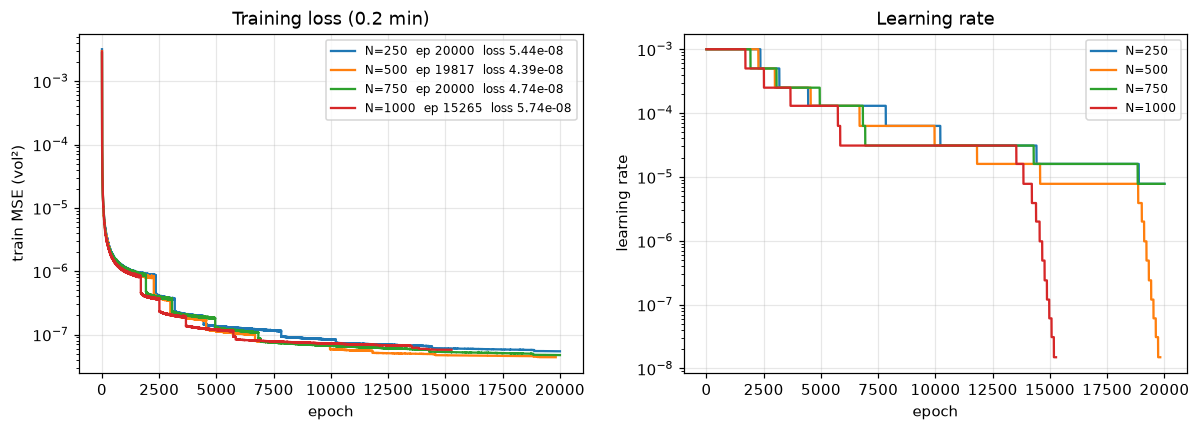

exit code 0


In [5]:
import os, re, signal, subprocess, sys, time
from IPython.display import clear_output

def read_log(h):
    rows = re.findall(r"epoch\s+(\d+)/\d+\s+loss (\S+)\s+lr (\S+)", (LOG_DIR / f"{PREFIX}_{h}.log").read_text()) \
        if (LOG_DIR / f"{PREFIX}_{h}.log").exists() else []
    return np.array(rows, dtype=float).reshape(-1, 3)

def plot_progress(elapsed):
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
    for h in SIZES:
        r = read_log(h)
        if len(r):
            a1.semilogy(r[:, 0], r[:, 1], label=f"N={h}  ep {int(r[-1, 0])}  loss {r[-1, 1]:.2e}")
            a2.semilogy(r[:, 0], r[:, 2], label=f"N={h}")
    a1.set(xlabel="epoch", ylabel="train MSE (vol²)", title=f"Training loss ({elapsed / 60:.1f} min)")
    a2.set(xlabel="epoch", ylabel="learning rate", title="Learning rate")
    for a in (a1, a2):
        a.grid(alpha=0.3)
        if a.lines: a.legend(fontsize=8)
    plt.show()

proc = subprocess.Popen([sys.executable, "-m", "src.train_ann", "hagan_1d_1y", *map(str, SIZES),
                         *(["--log-inputs"] if LOG_INPUTS else [])],
                        start_new_session=True)  # own process group, so an interrupt can stop all workers
t0 = time.time()
try:
    while proc.poll() is None:
        clear_output(wait=True); plot_progress(time.time() - t0)
        time.sleep(10)
except KeyboardInterrupt:
    os.killpg(proc.pid, signal.SIGTERM)
    print("training stopped")
clear_output(wait=True); plot_progress(time.time() - t0)
print("exit code", proc.wait())

--- N=250 ---
20000 epochs, final train MSE 5.441e-08
--- N=500 ---
19817 epochs, final train MSE 4.388e-08
--- N=750 ---


20000 epochs, final train MSE 4.741e-08
--- N=1000 ---
15265 epochs, final train MSE 5.744e-08


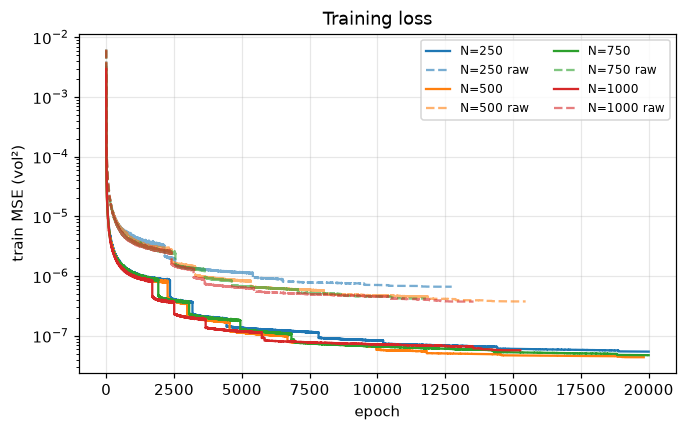

In [6]:
nets, losses = {}, {}
for h in SIZES:
    path = MODEL_DIR / f"{PREFIX}_{h}.pt"
    net = SABRNet(h, log_inputs=LOG_INPUTS)
    print(f"--- N={h} ---")
    if path.exists():
        ckpt = torch.load(path)
        net.load_state_dict(ckpt["state"])
        losses[h] = ckpt["losses"]
        done = ckpt.get("stopped", True) or len(losses[h]) >= EPOCHS
    else:  # same recipe as the cell above, in-process
        net.set_input_range(X_train)
        losses[h] = train(net, X_train, y_train, epochs=EPOCHS)
        torch.save({"state": net.state_dict(), "losses": losses[h]}, path)
        done = True
    print(f"{len(losses[h])} epochs{'' if done else ' (STILL TRAINING: latest checkpoint)'}, final train MSE {losses[h][-1]:.3e}")
    nets[h] = net.eval()

# raw-input models for comparison (dashed in the plots below)
ref_nets, ref_losses = {}, {}
for h in SIZES if LOG_INPUTS else []:
    if (path := MODEL_DIR / f"ann_{h}.pt").exists():
        ckpt = torch.load(path)
        ref_nets[h] = SABRNet(h)
        ref_nets[h].load_state_dict(ckpt["state"])
        ref_nets[h].eval()
        ref_losses[h] = ckpt["losses"]

fig, ax = plt.subplots(figsize=(7, 4))
for h in SIZES:
    line, = ax.semilogy(losses[h], label=f"N={h}")
    if h in ref_losses:
        ax.semilogy(ref_losses[h], "--", color=line.get_color(), alpha=0.6, label=f"N={h} raw")
ax.set(xlabel="epoch", ylabel="train MSE (vol²)", title="Training loss")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)

## 3. Out-of-sample error on the 50k test set
Errors are in implied-vol basis points (1 bp = 0.01%). The paper reports no aggregate test metric, so these numbers are our own baseline. With `LOG_INPUTS`, each metric shows the log-input model next to the raw-input one.

In [7]:
def metrics(e):
    return {"MAE (bp)": np.abs(e).mean(), "RMSE (bp)": np.sqrt((e**2).mean()),
            "p99 |err| (bp)": np.percentile(np.abs(e), 99), "max |err| (bp)": np.abs(e).max()}

TAG = "log" if LOG_INPUTS else "raw"
err = {h: (nets[h].predict(X_test) - y_test) * 1e4 for h in SIZES}
ref_err = {h: (ref_nets[h].predict(X_test) - y_test) * 1e4 for h in ref_nets}
rows = {(TAG, h): metrics(e) for h, e in err.items()} | {("raw", h): metrics(e) for h, e in ref_err.items()}
pd.DataFrame(rows).T.rename_axis(["inputs", "N"]).unstack("inputs").round(3)

MAE (bp)        RMSE (bp)        p99 |err| (bp)         max |err| (bp)  \
inputs      log    raw       log    raw            log     raw            log   
N                                                                               
250       1.322  4.718     2.137  7.039          8.291  25.063         40.415   
500       1.158  3.599     1.899  5.392          7.448  18.991         41.904   
750       1.195  3.777     1.938  5.632          7.611  20.073         38.706   
1000      1.289  3.550     2.179  5.265          8.700  18.479         53.164   

                 
inputs      raw  
N                
250     153.195  
500     133.111  
750     130.306  
1000    131.003

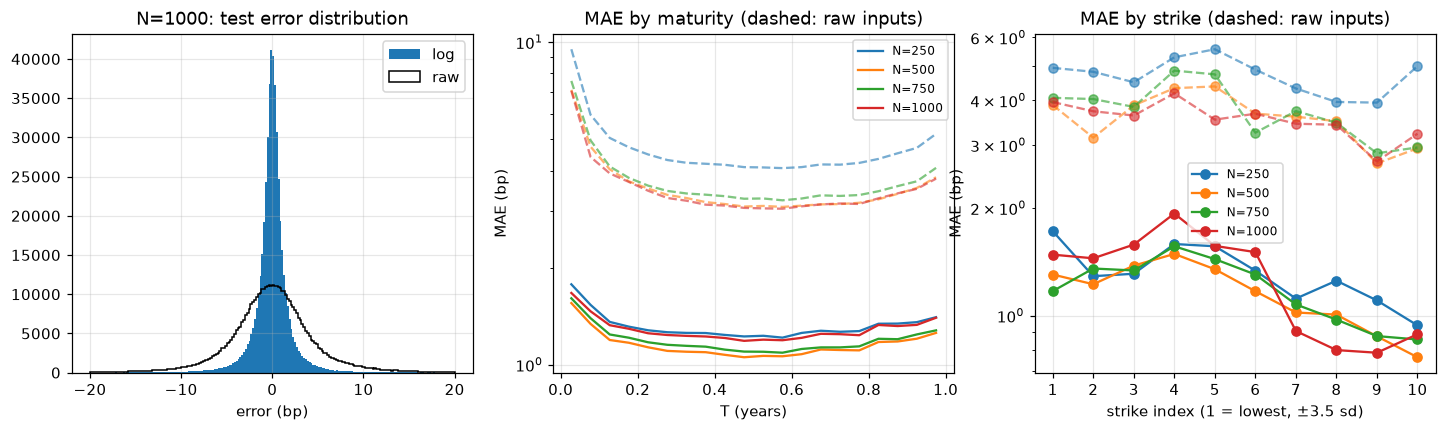

In [8]:
H = max(SIZES)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(err[H].ravel(), bins=200, range=(-20, 20), label=TAG)
if H in ref_err:
    axes[0].hist(ref_err[H].ravel(), bins=200, range=(-20, 20), histtype="step", color="k", label="raw")
axes[0].set(xlabel="error (bp)", title=f"N={H}: test error distribution"); axes[0].legend()
T_test = X_test[:, 0]
bins = np.linspace(T_test.min(), T_test.max(), 21)
idx = np.digitize(T_test, bins)
mae_T = lambda e: [np.abs(e[idx == i]).mean() for i in range(1, len(bins))]
for h in SIZES:
    line, = axes[1].plot((bins[:-1] + bins[1:]) / 2, mae_T(err[h]), label=f"N={h}")
    axes[2].plot(range(1, 11), np.abs(err[h]).mean(0), "o-", color=line.get_color(), label=f"N={h}")
    if h in ref_err:
        axes[1].plot((bins[:-1] + bins[1:]) / 2, mae_T(ref_err[h]), "--", color=line.get_color(), alpha=0.6)
        axes[2].plot(range(1, 11), np.abs(ref_err[h]).mean(0), "o--", color=line.get_color(), alpha=0.6)
axes[1].set(xlabel="T (years)", ylabel="MAE (bp)", title="MAE by maturity (dashed: raw inputs)", yscale="log")
axes[2].set(xlabel="strike index (1 = lowest, ±3.5 sd)", ylabel="MAE (bp)", title="MAE by strike (dashed: raw inputs)",
            yscale="log", xticks=range(1, 11))
for a in axes[1:]: a.legend(fontsize=8)
for a in axes: a.grid(alpha=0.3)

## 4. Paper Figures 2–4: smiles from all four networks
Both the Hagan reference and the ANN outputs are taken at the 10 strikes and passed through a cubic spline (§4.3), so the error below is the network error alone, evaluated on a fine strike grid. Units: vol %. Dashed: the largest raw-input network, for comparison.

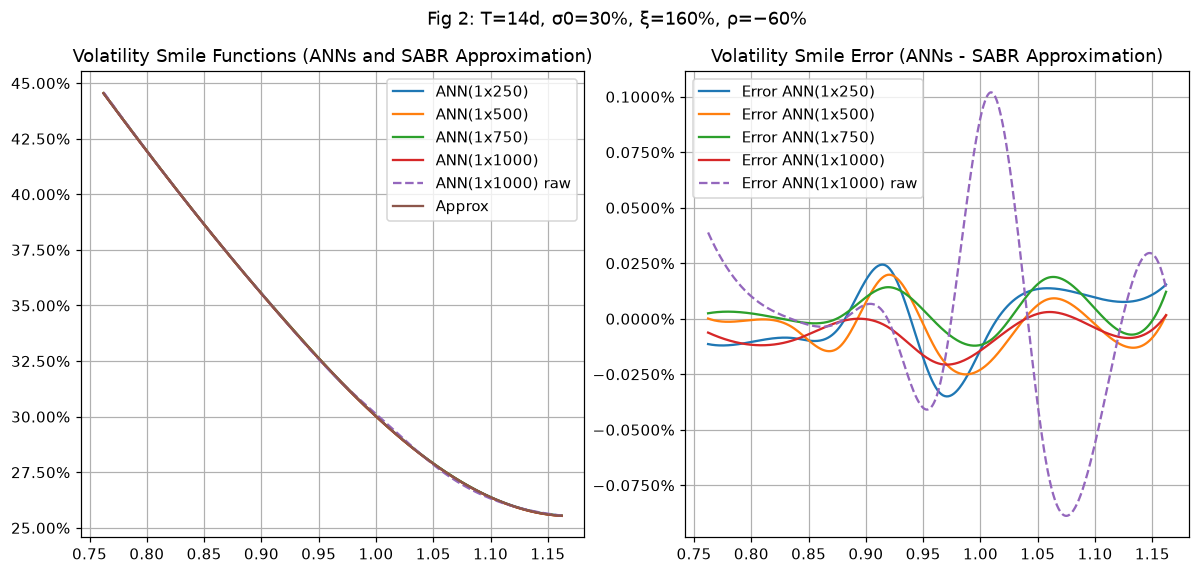

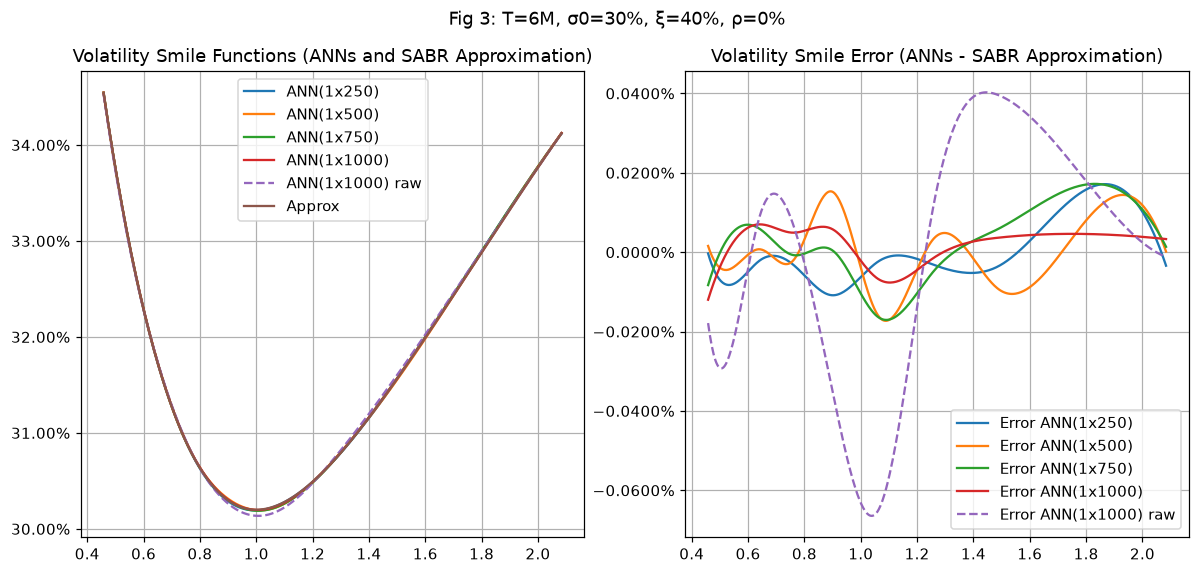

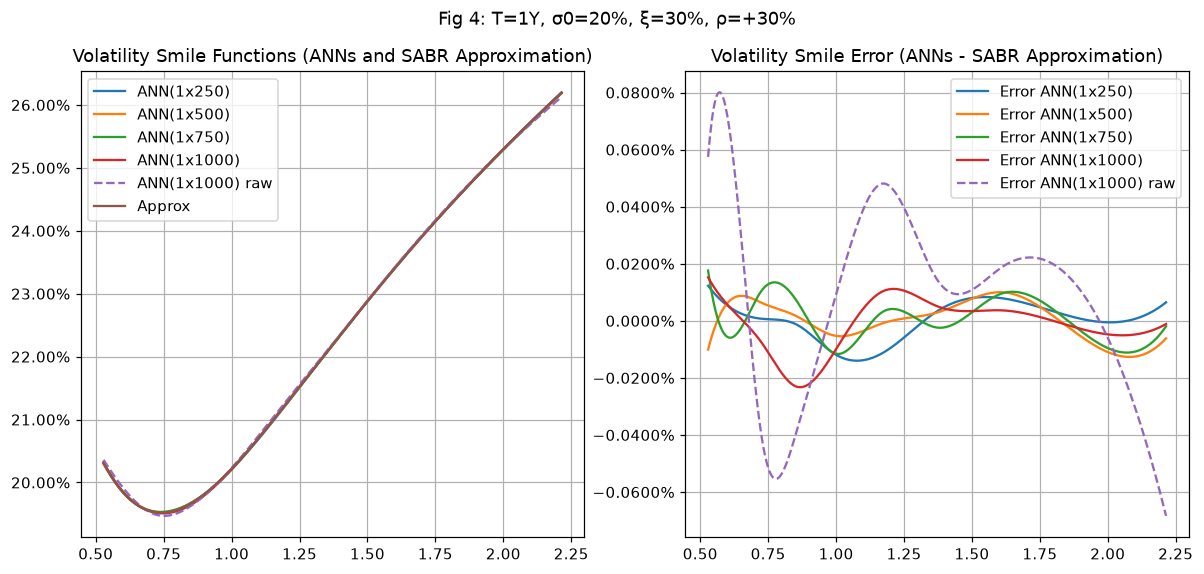

,figure,inputs,N,ours min (%),ours max (%),paper min (%),paper max (%),within paper range
0,Fig 2,log,250,-0.0350,0.0244,-0.030,0.10,False
1,Fig 2,log,500,-0.0250,0.0198,-0.030,0.10,True
2,Fig 2,log,750,-0.0121,0.0188,-0.030,0.10,True
3,Fig 2,log,1000,-0.0207,0.0030,-0.030,0.10,True
4,Fig 2,raw,1000,-0.0888,0.1020,-0.030,0.10,False
5,Fig 3,log,250,-0.0109,0.0171,-0.015,0.02,True
6,Fig 3,log,500,-0.0173,0.0153,-0.015,0.02,False
7,Fig 3,log,750,-0.0171,0.0172,-0.015,0.02,False
8,Fig 3,log,1000,-0.0120,0.0070,-0.015,0.02,True
9,Fig 3,raw,1000,-0.0664,0.0403,-0.015,0.02,False


In [9]:
from matplotlib.ticker import PercentFormatter
from scipy.interpolate import CubicSpline

def smiles(T, a, nu, rho, net, n=500):
    K = make_strikes(1.0, T, a, rho, nu)
    Kf = np.linspace(K[0], K[-1], n)
    ref = CubicSpline(K, hagan_iv(1.0, K, T, a, 1.0, rho, nu))(Kf)
    ann = CubicSpline(K, net.predict(np.r_[T, a, nu, rho, K][None])[0])(Kf)
    return Kf, ref, ann

def paper_plot(K, ref, curves, what, decimals=(2, 4), suptitle=""):
    """Paper layout: functions on the left, ANN − Approx error on the right, y-axes in %."""
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5.5))
    for name, c in curves.items():
        ls = "--" if "raw" in name else "-"
        left.plot(K, c, ls, label=name)
        right.plot(K, c - ref, ls, label=f"Error {name}")
    left.plot(K, ref, label="Approx")
    left.set_title(f"{what} Functions (ANNs and SABR Approximation)")
    right.set_title(f"{what} Error (ANNs - SABR Approximation)")
    for ax, dec in zip((left, right), decimals):
        ax.yaxis.set_major_formatter(PercentFormatter(1, dec))
        ax.grid(); ax.legend()
    fig.suptitle(suptitle)
    plt.show()

FIGS = {  # name: (T, sigma0, xi, rho), paper error range in vol %
    "Fig 2: T=14d, σ0=30%, ξ=160%, ρ=−60%": ((14 / 365, 0.30, 1.60, -0.60), (-0.03, 0.10)),
    "Fig 3: T=6M, σ0=30%, ξ=40%, ρ=0%":     ((0.5, 0.30, 0.40, 0.00), (-0.015, 0.02)),
    "Fig 4: T=1Y, σ0=20%, ξ=30%, ρ=+30%":   ((1.0, 0.20, 0.30, 0.30), (-0.025, 0.02)),
}
rows = []
for name, (p, paper) in FIGS.items():
    curves = {}
    for h, net, tag in [(h, nets[h], TAG) for h in SIZES] + [(H, ref_nets[H], "raw")] * (H in ref_nets):
        Kf, ref, ann = smiles(*p, net)
        curves[f"ANN(1x{h})" + (" raw" if tag == "raw" and LOG_INPUTS else "")] = ann
        e = (ann - ref) * 100
        rows.append({"figure": name[:5], "inputs": tag, "N": h, "ours min (%)": e.min(), "ours max (%)": e.max(),
                     "paper min (%)": paper[0], "paper max (%)": paper[1],
                     "within paper range": paper[0] <= e.min() and e.max() <= paper[1]})
    paper_plot(Kf, ref, curves, "Volatility Smile", suptitle=name)
pd.DataFrame(rows).round(4)

## 5. Paper Figures 5–6: smile, CDF and PDF (largest trained N)
Black prices with F=1 and no discounting: CDF(K) = 1 + ∂C/∂K and PDF(K) = ∂²C/∂K², both by finite differences on the spline smile. Units are % (probability × 100, density × 100), as in the paper. Dashed: the raw-input network of the same size.

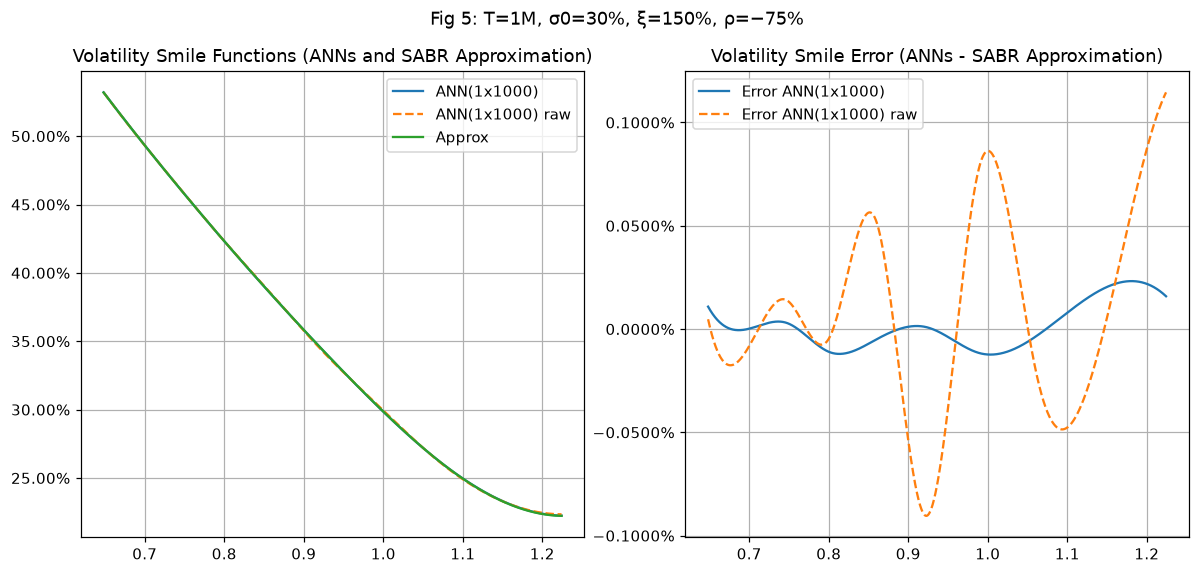

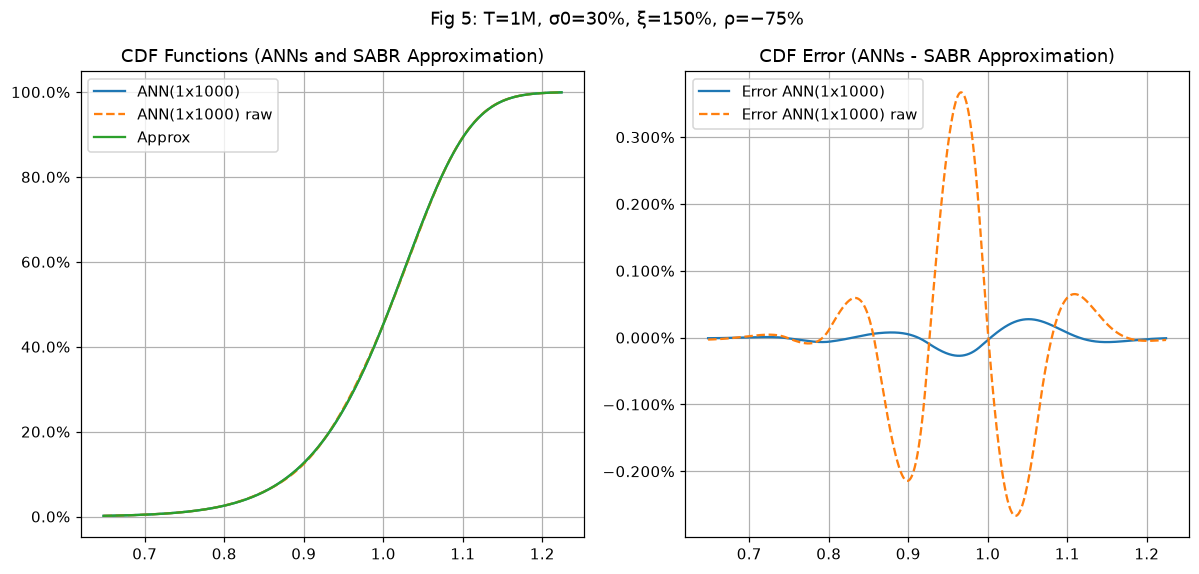

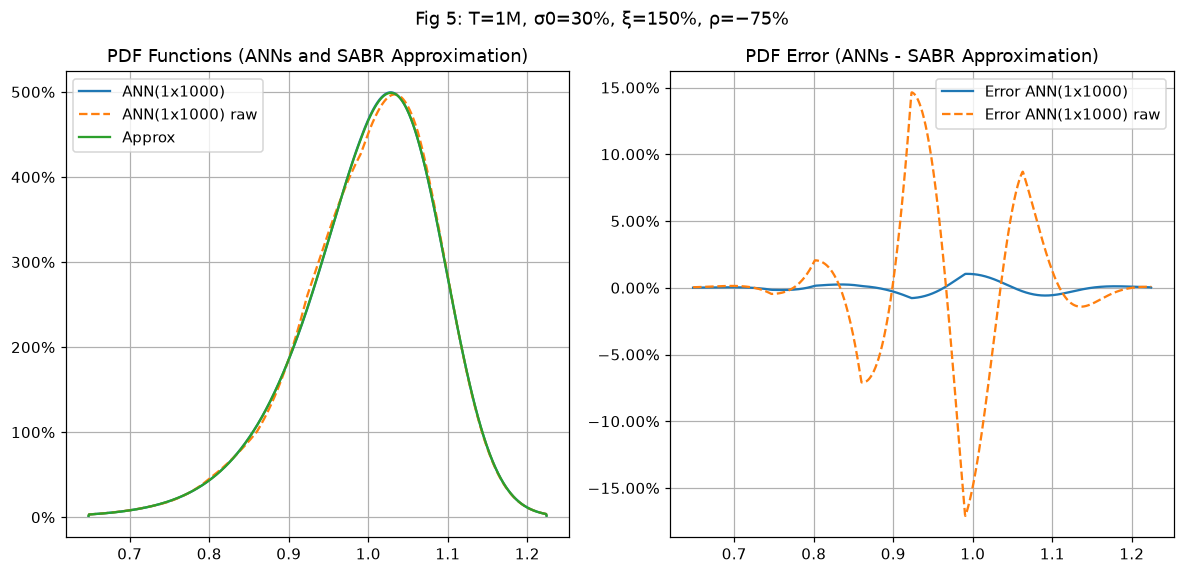

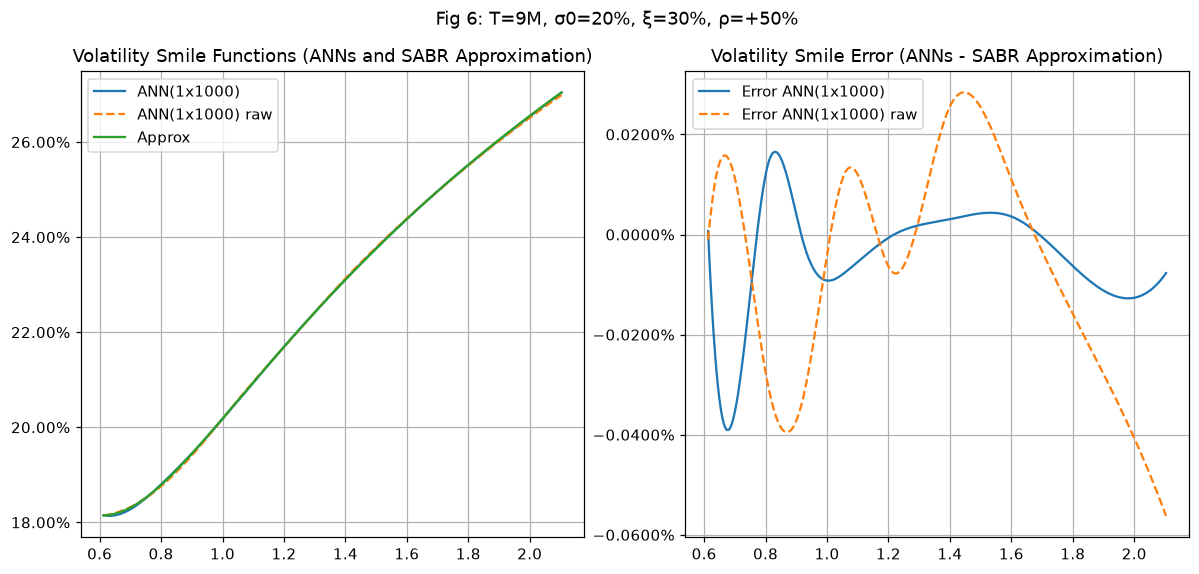

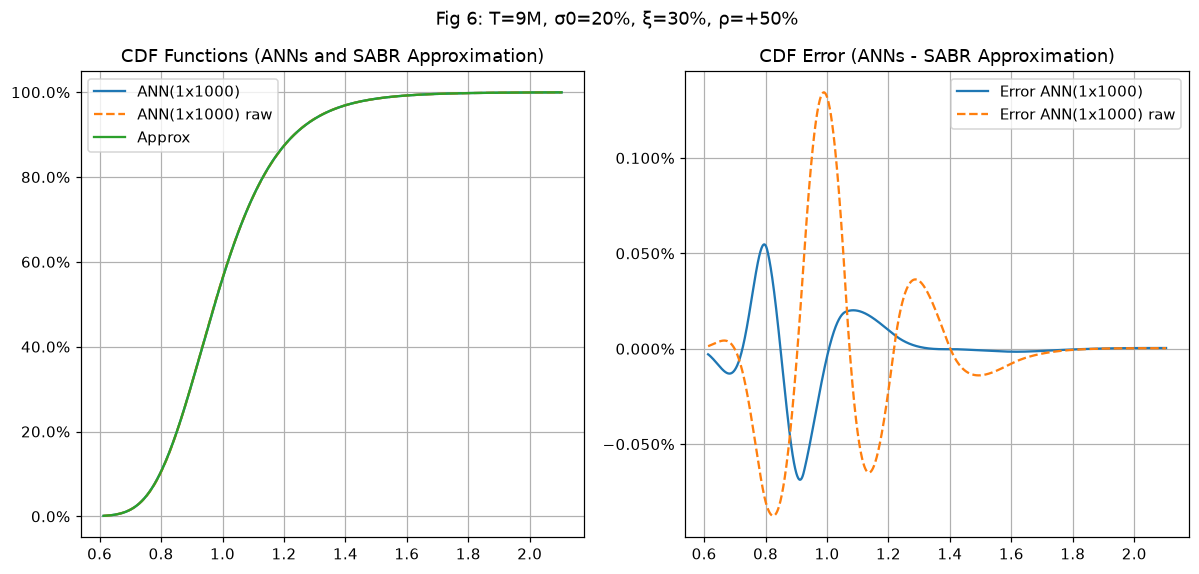

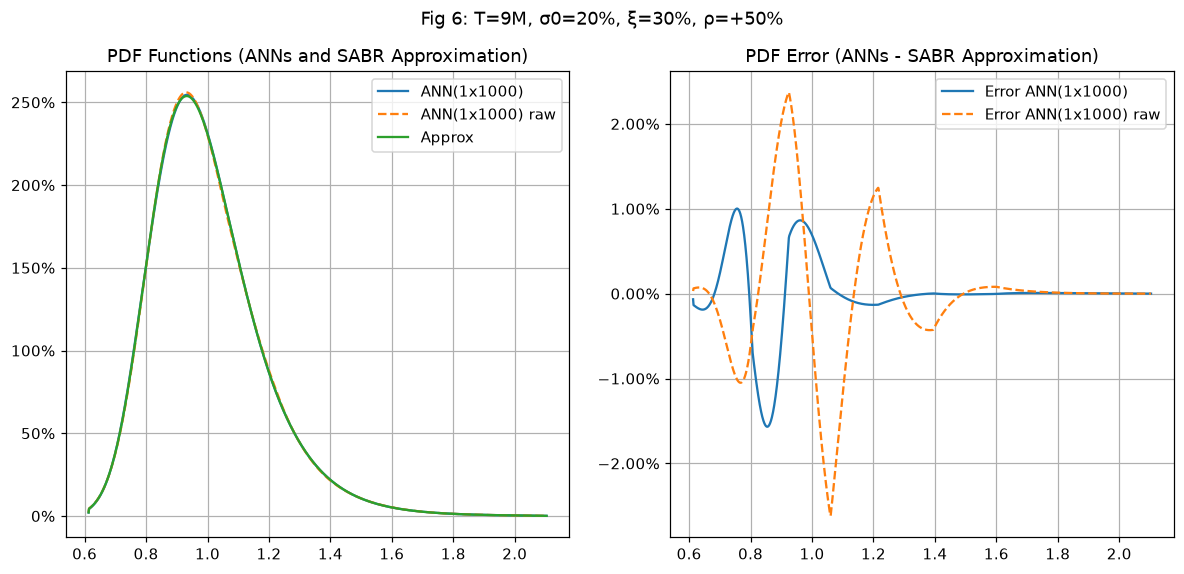

,figure,quantity,inputs,ours min (%),ours max (%),paper min (%),paper max (%),within paper range
0,Fig 5,Volatility Smile,log,-0.0124,0.0232,-0.0300,0.020,False
1,Fig 5,Volatility Smile,raw,-0.0904,0.1146,-0.0300,0.020,False
2,Fig 5,CDF,log,-0.0272,0.0276,-0.0600,0.040,True
3,Fig 5,CDF,raw,-0.2667,0.3671,-0.0600,0.040,False
4,Fig 5,PDF,log,-0.7745,1.0410,-2.0000,2.000,True
5,Fig 5,PDF,raw,-17.0877,14.6390,-2.0000,2.000,False
6,Fig 6,Volatility Smile,log,-0.0391,0.0165,-0.0025,0.015,False
7,Fig 6,Volatility Smile,raw,-0.0562,0.0284,-0.0025,0.015,False
8,Fig 6,CDF,log,-0.0687,0.0547,-0.0200,0.030,False
9,Fig 6,CDF,raw,-0.0876,0.1344,-0.0200,0.030,False


In [10]:
def black_call(K, sig, T):
    s = sig * np.sqrt(T)
    d1 = (-np.log(K) + s**2 / 2) / s
    return norm.cdf(d1) - K * norm.cdf(d1 - s)

def cdf_pdf(K, sig, T):
    dC = np.gradient(black_call(K, sig, T), K)
    return 1 + dC, np.gradient(dC, K)

FIGS2 = {  # paper: smile range, CDF range, max |PDF error|  (all in %)
    "Fig 5: T=1M, σ0=30%, ξ=150%, ρ=−75%": ((1 / 12, 0.30, 1.50, -0.75), (-0.03, 0.02), (-0.06, 0.04), 2.0),
    "Fig 6: T=9M, σ0=20%, ξ=30%, ρ=+50%":  ((0.75, 0.20, 0.30, 0.50), (-0.0025, 0.015), (-0.02, 0.03), 0.4),
}
rows = []
models = {TAG: nets[H]} | ({"raw": ref_nets[H]} if H in ref_nets else {})
for name, (p, s_rng, c_rng, pdf_max) in FIGS2.items():
    T = p[0]
    out = {tag: smiles(*p, net, n=2000) for tag, net in models.items()}
    Kf, ref, _ = out[TAG]
    cr, pr = cdf_pdf(Kf, ref, T)
    anns = {tag: (a, *cdf_pdf(Kf, a, T)) for tag, (_, _, a) in out.items()}
    for j, (what, r, rng, dec) in enumerate([("Volatility Smile", ref, s_rng, (2, 4)),
                                             ("CDF", cr, c_rng, (1, 3)),
                                             ("PDF", pr, (-pdf_max, pdf_max), (0, 2))]):
        curves = {f"ANN(1x{H})" + (" raw" if tag == "raw" and LOG_INPUTS else ""): v[j] for tag, v in anns.items()}
        paper_plot(Kf, r, curves, what, dec, suptitle=name)
        for tag, v in anns.items():
            e = (v[j] - r) * 100
            rows.append({"figure": name[:5], "quantity": what, "inputs": tag, "ours min (%)": e.min(), "ours max (%)": e.max(),
                         "paper min (%)": rng[0], "paper max (%)": rng[1],
                         "within paper range": rng[0] <= e.min() and e.max() <= rng[1]})
pd.DataFrame(rows).round(4)

## 6. How accurately does the ANN reproduce integration?

The reference is the **integration IV**, evaluated on the same held-out 50,000 smiles (ten strikes each) used for every network. Error = ANN − integration; **1 IV bp = 0.0001** decimal volatility. This measures the network's approximation error; it does not measure integration's own error against the exact SABR model.

The table compares all available fine-tuned networks. The plots use **log inputs, N=750**, fixed in advance; change `DETAIL_MODEL` to inspect another row. Each curve pools errors within a parameter bucket: blue is mean absolute error, orange is the 99th percentile of absolute error. The heatmap shows where vol of vol and correlation interact. These are averages over the other sampled parameters, not controlled one-parameter sweeps.

In [1]:
DETAIL_MODEL = ("log", 750)
with np.load(DATA_DIR / "ln_parity_1d_1y.npz") as integration_data:
    integration_X = integration_data["X_test"]
    integration_y = integration_data["y_test"]
integration_mask = np.isfinite(integration_y)
assert integration_mask.any(), "No finite integration reference labels."

integration_rows = {}
detail_prediction = None
previous_threads = torch.get_num_threads()
torch.set_num_threads(1)
try:
    for inputs, log in (("log", True), ("raw", False)):
        for hidden in (250, 500, 750, 1000):
            prefix = "ann_log" if log else "ann"
            path = MODEL_DIR / f"{prefix}_{hidden}_ln.pt"
            if not path.exists():
                continue
            checkpoint = torch.load(path, map_location="cpu", weights_only=True)
            net = SABRNet(hidden, log_inputs=log)
            net.load_state_dict(checkpoint["state"])
            net.eval()
            prediction = np.vstack([net.predict(integration_X[i:i + 2048])
                                    for i in range(0, len(integration_X), 2048)])
            assert np.isfinite(prediction).all(), f"Non-finite ANN output: {path.name}"
            error_bp = (prediction - integration_y) * 1e4
            epochs = len(checkpoint["losses"])
            integration_rows[(inputs, hidden)] = {
                **metrics(error_bp[integration_mask]),
                "checkpoint": "finished" if checkpoint.get("stopped", False) or epochs >= 20000 else "training",
            }
            if (inputs, hidden) == DETAIL_MODEL:
                detail_prediction = prediction
finally:
    torch.set_num_threads(previous_threads)
if detail_prediction is None:
    raise FileNotFoundError(f"Fine-tuned checkpoint missing for DETAIL_MODEL={DETAIL_MODEL}.")

detail_error = np.where(integration_mask, np.abs(detail_prediction - integration_y) * 1e4, np.nan)
print(f"Reference: {len(integration_X):,} held-out smiles; {integration_mask.sum():,} finite IV labels "
      f"({integration_mask.mean():.2%}). All errors below are IV bp.")
display(pd.DataFrame.from_dict(integration_rows, orient="index").rename_axis(["inputs", "N"]).round(3))

Reference: 50,000 held-out smiles; 500,000 finite IV labels (100.00%). All errors below are IV bp.


MAE (bp)  RMSE (bp)  p99 |err| (bp)  max |err| (bp) checkpoint
inputs N                                                                   
log    250      1.130      1.860           7.226          53.106   finished
       500      1.060      1.776           7.033          46.087   finished
       750      1.043      1.740           7.037          44.693   finished
       1000     1.165      1.988           7.940          42.249   finished
raw    250      4.076      6.037          21.215         139.647   training
       500      3.301      4.876          16.972         154.075   training
       750      3.409      5.018          17.491         119.967   training
       1000     3.254      4.777          16.625         128.812   training

Largest observed error: 44.7 IV bp at T=0.991Y, α=48.7%, ν₁ₘ=382.9%, ρ=+0.325, K/F=0.277 (strike 3/10).


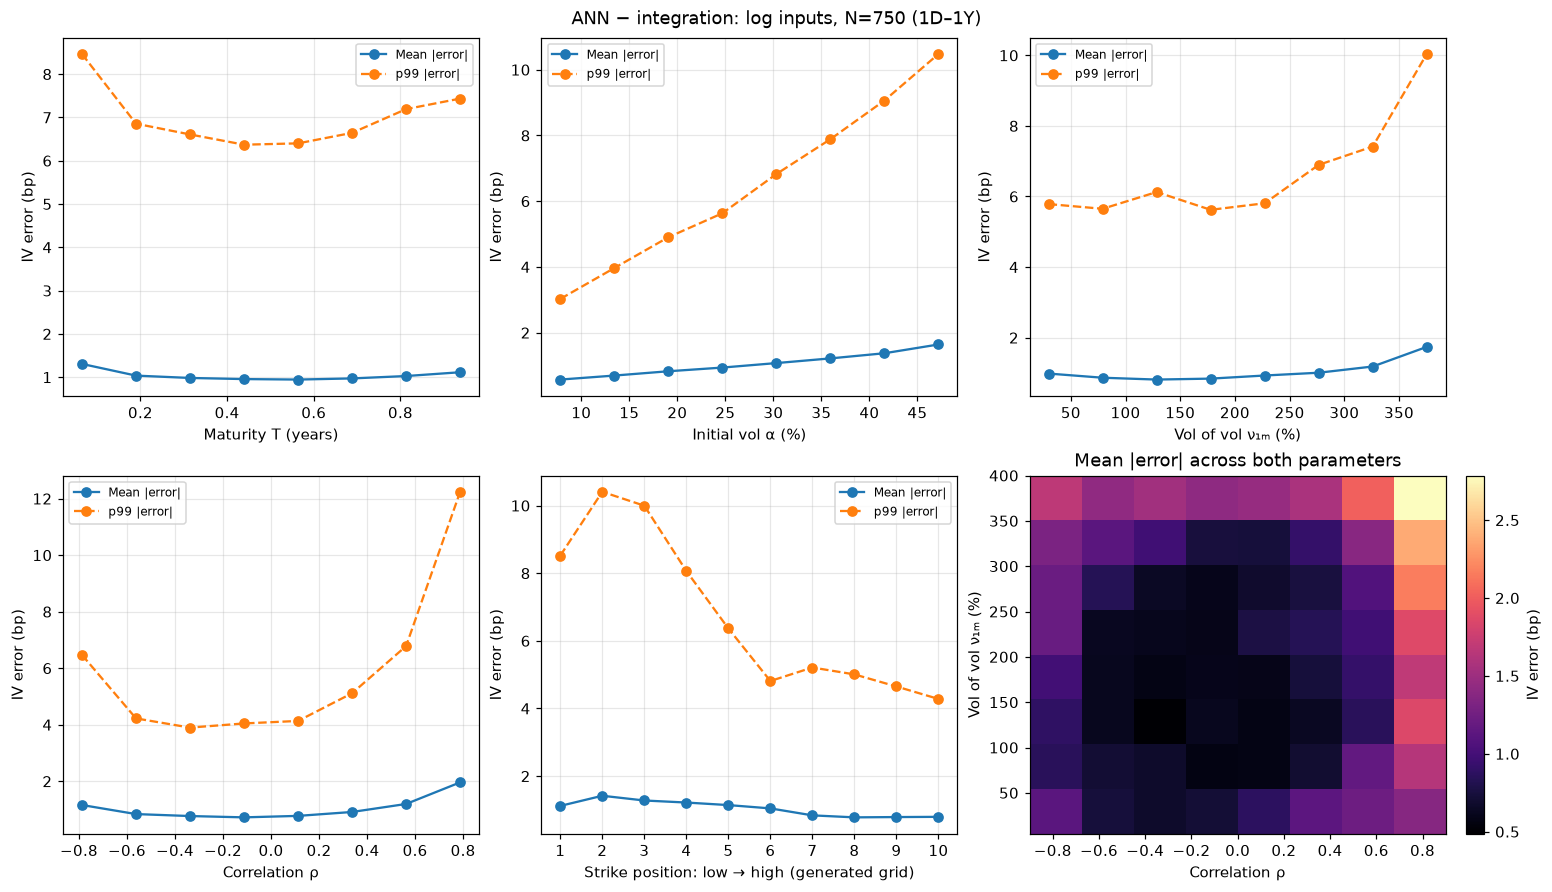

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8), constrained_layout=True)
flat_error = detail_error.ravel()
nu1m = integration_X[:, 2] * np.sqrt(12 * integration_X[:, 0])
parameters = [
    (integration_X[:, 0], np.linspace(1 / 365, 1, 9), "Maturity T (years)"),
    (100 * integration_X[:, 1], np.linspace(5, 50, 9), "Initial vol α (%)"),
    (100 * nu1m, np.linspace(5, 400, 9), "Vol of vol ν₁ₘ (%)"),
    (integration_X[:, 3], np.linspace(-0.9, 0.9, 9), "Correlation ρ"),
]
for ax, (values, edges, label) in zip(axes.flat, parameters):
    buckets = pd.cut(np.repeat(values, integration_y.shape[1]), edges, include_lowest=True)
    grouped = pd.DataFrame({"bucket": buckets, "error": flat_error}).groupby("bucket", observed=False)["error"]
    centers = (edges[:-1] + edges[1:]) / 2
    ax.plot(centers, grouped.mean(), "o-", label="Mean |error|")
    ax.plot(centers, grouped.quantile(0.99), "o--", label="p99 |error|")
    ax.set(xlabel=label, ylabel="IV error (bp)")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

ax = axes[1, 1]
positions = np.arange(1, integration_y.shape[1] + 1)
ax.plot(positions, np.nanmean(detail_error, axis=0), "o-", label="Mean |error|")
ax.plot(positions, np.nanpercentile(detail_error, 99, axis=0), "o--", label="p99 |error|")
ax.set(xlabel="Strike position: low → high (generated grid)", ylabel="IV error (bp)", xticks=positions)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

nu_edges, rho_edges = np.linspace(5, 400, 9), np.linspace(-0.9, 0.9, 9)
interaction = pd.DataFrame({
    "nu": pd.cut(100 * nu1m, nu_edges, include_lowest=True),
    "rho": pd.cut(integration_X[:, 3], rho_edges, include_lowest=True),
    "error": np.nanmean(detail_error, axis=1),
}).pivot_table(index="nu", columns="rho", values="error", observed=False)
ax = axes[1, 2]
heat = ax.pcolormesh(rho_edges, nu_edges, interaction.to_numpy(), cmap="magma", shading="flat")
ax.set(xlabel="Correlation ρ", ylabel="Vol of vol ν₁ₘ (%)", title="Mean |error| across both parameters")
fig.colorbar(heat, ax=ax, label="IV error (bp)")
fig.suptitle(f"ANN − integration: {DETAIL_MODEL[0]} inputs, N={DETAIL_MODEL[1]} (1D–1Y)")
plt.show()

worst_row, worst_strike = np.unravel_index(np.nanargmax(detail_error), detail_error.shape)
print(f"Largest observed error: {detail_error[worst_row, worst_strike]:.1f} IV bp at "
      f"T={integration_X[worst_row, 0]:.3f}Y, α={integration_X[worst_row, 1]:.1%}, "
      f"ν₁ₘ={nu1m[worst_row]:.1%}, ρ={integration_X[worst_row, 3]:+.3f}, "
      f"K/F={integration_X[worst_row, 4 + worst_strike]:.3f} (strike {worst_strike + 1}/10).")

## 7. Synthetic market calibration

Given IV quotes at fixed strikes, estimate **α, ν₁ₘ and ρ** using Hagan, integration or the fine-tuned log ANN (N=750). Maturity and forward are known; β=1.

We use six synthetic smiles from 14 days to one year. Each quote is an integration IV plus independent Gaussian noise with standard deviation **1 IV bp** (fixed seed). Only noisy cases are compared. The forward is 100 and normalized internally; annual ν = ν₁ₘ / √(12T).

**What is fitted?** For each method, minimize equal-weight IV mean squared error:

$$L(\theta)=\frac{1}{n}\sum_{i=1}^n\bigl[\sigma_{\mathrm{method}}(K_i;\theta)-\sigma_i^{\mathrm{quote}}\bigr]^2,\qquad\theta=(\alpha,\nu_{1M},\rho).$$

**How?** SciPy's **SLSQP**, a constrained optimizer, uses central finite differences to estimate derivatives. All methods use the same three starting guesses, parameter bounds and strike-coverage constraints; we keep the lowest-MSE valid converged fit. The code divides residuals by 0.01 before squaring to set a useful numerical scale, which does not change the minimizer. Hagan and integration evaluate the quote strikes directly; the ANN splines its ten predicted IVs to those strikes without extrapolation. The generating parameters are never supplied to the optimizer.

**MSE, MLE or gradient descent?** MSE is the loss; SLSQP is the optimization algorithm. Under our independent, equal-variance Gaussian noise assumption, minimizing this MSE also gives maximum-likelihood parameter estimates (MLE). SLSQP is different from plain gradient descent. Adam was used earlier to train the ANN weights; calibration keeps those weights fixed and changes only the three SABR parameters.

**Should integration fit perfectly?** At the generating parameters it reproduces the clean smile, up to numerical precision. Added noise generally moves the seven quotes off the family of smiles described by three parameters, so even integration leaves residuals. The optimizer also has finite stopping tolerances and no guarantee of finding the global minimum. A small quote error need not imply exact recovery of the generating parameters.

Leave `RUN_CALIBRATION = False` to show saved results. Full calibration time includes all three starts and final validation, excludes quote generation and checkpoint loading, and is the median of three repetitions using one CPU thread. Concurrent training can affect timings.

In [1]:
from src.calibration import benchmark, synthetic_quotes, load_ann, predict

RUN_CALIBRATION = False
calibration_path = DATA_DIR.parent.parent / "wiki" / "research" / "results" / "calibration.csv"
if RUN_CALIBRATION:
    benchmark(repeats=3, output=calibration_path)

calibration_results = pd.read_csv(calibration_path) if calibration_path.exists() else pd.DataFrame()
calibration_cases = synthetic_quotes()
if not calibration_results.empty:
    calibration_results = calibration_results.loc[calibration_results.quotes == "noisy"].copy()
if calibration_results.empty:
    print("No calibration benchmark yet. Set RUN_CALIBRATION = True or run:")
    print(".venv/bin/python -m src.calibration")
else:
    print("Saved synthetic benchmark:", calibration_path)
    print("Repetitions per fit:", calibration_results.repeats.unique())
    display(calibration_results[["case", "method", "success", "rmse_bp", "seconds"]])

Saved synthetic benchmark: /Users/sindreveum/code/AQF-darth-hedger/results/calibration.csv
Repetitions per fit: [3]


,case,method,success,rmse_bp,seconds
3,smile-1,hagan,True,0.302209,0.098955
4,smile-1,integration,True,0.304983,10.338365
5,smile-1,ann,True,0.506668,0.166695
9,smile-2,hagan,True,0.478376,0.062169
10,smile-2,integration,True,0.471083,10.874537
11,smile-2,ann,True,0.692654,0.129702
15,smile-3,hagan,True,0.941536,0.058358
16,smile-3,integration,True,0.941928,7.022462
17,smile-3,ann,True,0.912404,0.216621
21,smile-4,hagan,True,0.558811,0.070905


### 7.1 Fit accuracy and calibration speed

IV errors are measured against the quotes supplied to the optimizer, in bp (1 bp = 0.0001 decimal IV). The table averages per-smile MAE and RMSE over successful fits and shows the worst smile RMSE. Timing is the median across smiles of each fit's median repeated runtime; failed fits are counted explicitly. This is **full calibration time**, including all three starts, rather than one smile evaluation.

In [2]:
if not calibration_results.empty:
    cal_ok = calibration_results[calibration_results.success]
    cal_summary = cal_ok.groupby("method").agg(
        successful_fits=("success", "size"),
        mean_mae_bp=("mae_bp", "mean"),
        mean_rmse_bp=("rmse_bp", "mean"),
        worst_rmse_bp=("rmse_bp", "max"),
        median_seconds=("seconds", "median"),
        mean_evaluations=("evaluations", "mean"),
    ).reindex(calibration_results.groupby("method").size().index)
    cal_summary["failed_fits"] = calibration_results.groupby("method")["success"].agg(lambda s: (~s).sum())
    display(cal_summary.round(4))
    if (~calibration_results.success).any():
        display(calibration_results.loc[~calibration_results.success, ["case", "quotes", "method", "message"]])

,successful_fits,mean_mae_bp,mean_rmse_bp,worst_rmse_bp,median_seconds,mean_evaluations,failed_fits
method,,,,,,,
ann,6,0.5661,0.6799,0.9124,0.2447,339.8333,0
hagan,6,0.5058,0.6053,0.9415,0.0668,379.6667,0
integration,6,0.5046,0.6048,0.9419,12.8757,413.6667,0


### 7.2 One example: noisy quotes, fitted smiles and parameter recovery

The error panel compares each fit with the noisy quotes. The dashed integration curve is the clean generating smile, shown only as a diagnostic. The table compares recovered parameters with the known generating values; these values would be unavailable for real market quotes. Hagan can compensate for approximation error by changing parameters, and the ANN can compensate for its surrogate error in the same way.

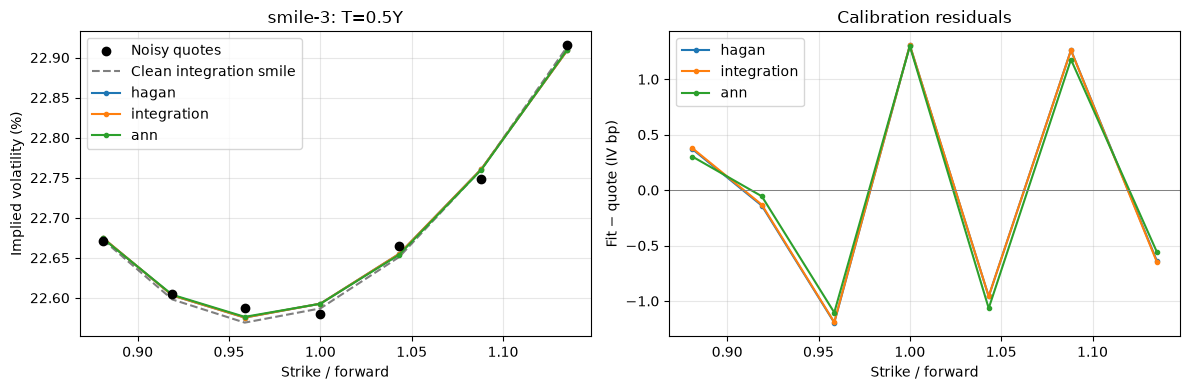

,alpha,nu1m,rho
Generating parameters,0.224131,1.030912,0.046863


,success,alpha,nu1m,rho,rmse_bp,seconds
method,,,,,,
hagan,True,0.22424,1.00555,0.04565,0.94154,0.05836
integration,True,0.22425,1.01275,0.04626,0.94193,7.02246
ann,True,0.22435,1.00262,0.04836,0.91240,0.21662


In [3]:
if not calibration_results.empty:
    example_name, example_kind, example_quotes, example_truth = next(
        c for c in calibration_cases if c[0] == "smile-3" and c[1] == "noisy")
    example_rows = calibration_results[
        (calibration_results.case == example_name) & (calibration_results.quotes == example_kind)]
    example_net = load_ann()
    clean_quotes = next(c[2] for c in calibration_cases if c[0] == example_name and c[1] == "noiseless")
    m = example_quotes.moneyness
    fig, (ax, err) = plt.subplots(1, 2, figsize=(12, 4))
    ax.scatter(m, example_quotes.ivs * 100, color="black", label="Noisy quotes", zorder=5)
    ax.plot(m, clean_quotes.ivs * 100, "k--", alpha=0.5, label="Clean integration smile")
    for row in example_rows[example_rows.success].itertuples():
        fitted = predict(example_quotes, [row.alpha, row.nu1m, row.rho], row.method, example_net)
        ax.plot(m, fitted * 100, ".-", label=row.method)
        err.plot(m, (fitted - example_quotes.ivs) * 1e4, ".-", label=row.method)
    ax.set(xlabel="Strike / forward", ylabel="Implied volatility (%)", title=f"{example_name}: T={example_quotes.maturity:g}Y")
    err.set(xlabel="Strike / forward", ylabel="Fit − quote (IV bp)", title="Calibration residuals")
    err.axhline(0, color="grey", lw=0.7)
    for a in (ax, err):
        a.legend(); a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    recovery = example_rows[["method", "success", "alpha", "nu1m", "rho", "rmse_bp", "seconds"]].set_index("method")
    display(pd.DataFrame([example_truth], columns=["alpha", "nu1m", "rho"], index=["Generating parameters"]))
    display(recovery.round(5))

### Using real quotes later

The same interface accepts `Quotes(maturity=T_years, forward=F, strikes=absolute_strikes, ivs=decimal_ivs)`, then `calibrate(quotes, method, net)` for `"hagan"`, `"integration"` or `"ann"`. The forward must be appropriate for that expiry. Strikes must be sorted and IVs must use the lognormal convention. This first version covers single expiries from 1D to 1Y with equal quote weights; it does not download market data or backtest hedges.

These six moderate synthetic cases test the calibration pipeline. They do not establish market fit quality, performance in the extreme training-domain corners, or a general speedup.